# Plot the output from the analysis of the virtual balloon timeseries

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy.stats import chi2
from scipy import interpolate
import scipy.signal 
warnings.simplefilter("ignore")

### Load in the data

In [4]:
# All packets propagate upward and at pi/6 radians North of East
#container = np.load('GaussEnv_ThHpiover6_1000B_20P_8omega0_Boussinesq.npz')

# All packets propagate upward and in random horizontal directions
container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq.npz')

# All packets propagate upward and in random horizontal directions, 3 packets per balloon
#container = np.load('GaussEnv_RandThH_1000B_3P_8omega0_Boussinesq.npz')

# All packets propagate in random vertical and horizontal directions
#container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq_randomUpDown.npz')

data = [container[key] for key in container]

# Constants, axes
rho_bar   = data[0]
Nref      = data[1]
f         = data[2]
frequency = data[3]
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98
      
# Properties of the input wave packets/timeseries 
total_flux_packets   = data[4] # (n_packet_frequencies, n_balloons)
total_energy_packets = data[5] # (n_packet_frequencies, n_balloons)
Ekh_packets          = data[6] # (n_packet_frequencies, n_balloons)
Ekv_packets          = data[7] # (n_packet_frequencies, n_balloons)
Ep_packets           = data[8] # (n_packet_frequencies, n_balloons)

# Outputs: analyzed totals
Etotal_scaled_total            = data[9]  # (n_balloons)
flux_total_eachpacket          = data[10] # (n_balloons, n_packet_frequencies+1)
flux_total_upw                 = data[11] # (n_balloons)
flux_total_upw_eachpacket      = data[12] # (n_balloons)
flux_total_absupw_eachpacket   = data[13] # (n_balloons)
flux_total_upw_correct_dtheta  = data[14] # (n_balloons)
flux_total_upw_correct_UpW     = data[15] # (n_balloons)
flux_total_uppt                = data[16] # (n_balloons)
flux_total_uppt_eachpacket     = data[17] # (n_balloons)
flux_total_absuppt_eachpacket  = data[18] # (n_balloons)
flux_total_uppt_correct_dtheta = data[19] # (n_balloons)
flux_total_uppt_correct_UpPT   = data[20] # (n_balloons)
flux_total_absupw              = data[21] # (n_balloons)
flux_total_absuppt             = data[22] # (n_balloons)
Etotal_total                   = data[23] # (n_balloons, n_packet_frequencies+1)
Ekh_total                      = data[24] # (n_balloons, n_packet_frequencies+1)
Ekv_total                      = data[25] # (n_balloons, n_packet_frequencies+1)
Ep_total                       = data[26] # (n_balloons, n_packet_frequencies+1)
up_power_total                 = data[27] # (n_balloons, n_packet_frequencies+1)

# Outputs: analyzed spectra
flux_spectrum_eachpacket          = data[28] # (nscales, n_balloons, n_packet_frequencies+1)
Etotal_scaled_spectrum            = data[29] # (nscales, n_balloons)
flux_spectrum_upw                 = data[30] # (nscales, n_balloons)
flux_spectrum_uppt                = data[31] # (nscales, n_balloons)
flux_spectrum_absupw              = data[32] # (nscales, n_balloons)
flux_spectrum_absuppt             = data[33] # (nscales, n_balloons)
flux_spectrum_upw_correct_dtheta  = data[34] # (nscales, n_balloons)
flux_spectrum_upw_correct_UpW     = data[35] # (nscales, n_balloons)
flux_spectrum_upw_eachpacket      = data[36] # (nscales, n_balloons)
flux_spectrum_absupw_eachpacket   = data[37] # (nscales, n_balloons)
flux_spectrum_uppt_correct_dtheta = data[38] # (nscales, n_balloons)
flux_spectrum_uppt_correct_UpPT   = data[39] # (nscales, n_balloons)
flux_spectrum_uppt_eachpacket     = data[40] # (nscales, n_balloons)
flux_spectrum_absuppt_eachpacket  = data[41] # (nscales, n_balloons)
Ekh_spectrum                      = data[42] # (nscales, n_balloons, n_packet_frequencies+1)
Ekv_spectrum                      = data[43] # (nscales, n_balloons, n_packet_frequencies+1)
Ep_spectrum                       = data[44] # (nscales, n_balloons, n_packet_frequencies+1)
up_power_spectrum                 = data[45] # (nscales, n_balloons, n_packet_frequencies+1)

nscales = flux_spectrum_eachpacket.shape[0]
n_balloons = flux_spectrum_eachpacket.shape[1]
n_packet_frequencies = flux_spectrum_eachpacket.shape[2] - 1

### The total momentum flux from each of the methods

In [3]:
# Values in Table 1

print('Total momentum flux (mPa)')
print('From packet timeseries (truth):',1000*rho_bar*np.nanmean(np.sum(total_flux_packets,axis=0)))
print('From scaled energy, combined timeseries:',1000*rho_bar*np.nanmean(Etotal_scaled_total))
print('From u-w, v-w cross-spectra, combined timeseries:',1000*rho_bar*np.nanmean(flux_total_eachpacket[:,-1]))
print('From u-w, v-w cross-spectra, summed over each packet:',1000*rho_bar*np.nanmean(np.nansum(flux_total_eachpacket[:,:-1],axis=1)))
print('From re(upw), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_upw))
print('From re(upw), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_upw_eachpacket))
print('From abs(upw), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_absupw))
print('From abs(upw), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_absupw_eachpacket))
print('From im(uppt), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_uppt))
print('From im(uppt), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_uppt_eachpacket))
print('From abs(uppt), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_absuppt_eachpacket))
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket))
print('Error in re(upw) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_UpW) - np.nanmean(flux_total_upw_eachpacket))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw_eachpacket))
print('attributed to errors in UpW:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_UpW) - np.nanmean(flux_total_upw_eachpacket))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw_eachpacket))
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket)) - temp
print('attributed to correlated dtheta, UpW errors:', temp)
print('difference between re(upw) and abs(upw):', 1000*rho_bar*(np.nanmean(flux_total_upw - flux_total_absupw)))
print('error in abs(upw):', 1000*rho_bar*(np.nanmean(flux_total_absupw - flux_total_upw_eachpacket)))
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket))
print('Error in re(upw) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
print('attributed to errors in UpW:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket)) - temp
print('attributed to correlated dtheta, UpW errors:', temp)
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket))
print('Error in im(uppt) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
print('attributed to errors in UpPT:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket)) - temp
print('attributed to correlated dtheta, UpPT errors:', temp)
print()

print('Flux from abs(upw):',1000*rho_bar*np.nanmean(flux_total_absupw))
temp = np.nanmean(flux_total_upw)/np.nanmean(flux_total_absupw)
print('Ratio of re(upw) to abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_absupw) - np.nanmean(flux_total_upw)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_upw)
print('Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw):', 100*(temp1/temp2))
print()

print('Flux from upw, correct dtheta:',1000*rho_bar*np.nanmean(flux_total_upw_correct_dtheta))
temp = np.nanmean(flux_total_upw)/np.nanmean(flux_total_upw_correct_dtheta)
print('Ratio of re(upw) to correct dtheta upw:', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_upw)
print('Percent of (scaled energy) - re(upw) explained by (upw, correct dtheta) - re(upw):', 100*(temp1/temp2))
print()

print('Flux from abs(uppt):',1000*rho_bar*np.nanmean(flux_total_absuppt))
temp = np.nanmean(flux_total_uppt)/np.nanmean(flux_total_absuppt)
print('Ratio of re(upw) to abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_absuppt) - np.nanmean(flux_total_uppt)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_uppt)
print('Percent of (scaled energy) - im(uppt) explained by abs(uppt) - im(uppt):', 100*(temp1/temp2))
print()

print('Flux from uppt, correct dtheta:',1000*rho_bar*np.nanmean(flux_total_uppt_correct_dtheta))
temp = np.nanmean(flux_total_uppt)/np.nanmean(flux_total_uppt_correct_dtheta)
print('Ratio of re(upw) to correct dtheta upw:', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_uppt_correct_dtheta) - np.nanmean(flux_total_uppt)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_uppt)
print('Percent of (scaled energy) - im(uppt) explained by (uppt, correct dtheta) - im(uppt):', 100*(temp1/temp2))
print()

Total momentum flux (mPa)
From packet timeseries (truth): 100.76373064943236
From scaled energy, combined timeseries: 103.11087070350243
From u-w, v-w cross-spectra, combined timeseries: 74.97237124214281
From u-w, v-w cross-spectra, summed over each packet: 96.16035988486048
From re(upw), combined timeseries: 71.71865440305349
From re(upw), summed over each packet: 96.1569358914455
From abs(upw), combined timeseries: 85.53983439627213
From abs(upw), summed over each packet: 96.16053596772996
From im(uppt), combined timeseries: 73.55034754876063
From im(uppt), summed over each packet: 98.70654242340635
From abs(uppt), summed over each packet: 100.8409285143205

Error in re(upw) due to superposition of packets (mPa): -24.438281488392015
attributed to errors in dtheta: -19.14350312015856
attributed to errors in UpW: -10.619016968586527
attributed to correlated dtheta, UpW errors: 5.32423860035307
difference between re(upw) and abs(upw): -13.821179993218639
error in abs(upw): -10.61710149

### Plot the momentum flux spectra

In [19]:
flux_spectrum = flux_spectrum_eachpacket[:,:,-1]
temp_flux = np.nanmean(flux_spectrum,axis=1)
temp_flux_eachpacket = np.nanmean(np.nansum(flux_spectrum_eachpacket[:,:,:-1],axis=2),axis=1)
temp_scaled_energy = np.nanmean(Etotal_scaled_spectrum,axis=1)
temp_flux_upw = np.nanmean(flux_spectrum_upw,axis=1)
temp_flux_uppt = np.nanmean(flux_spectrum_uppt,axis=1)
temp_flux_upw_correct_dtheta = np.nanmean(flux_spectrum_upw_correct_dtheta,axis=1)
temp_flux_upw_correct_UpW = np.nanmean(flux_spectrum_upw_correct_UpW,axis=1)
temp_flux_upw_eachpacket = np.nanmean(flux_spectrum_upw_eachpacket,axis=1)
temp_flux_absupw_eachpacket = np.nanmean(flux_spectrum_absupw_eachpacket,axis=1)
temp_flux_absupw = np.nanmean(flux_spectrum_absupw,axis=1)
temp_flux_uppt_eachpacket = np.nanmean(flux_spectrum_uppt_eachpacket,axis=1)
temp_flux_absuppt_eachpacket = np.nanmean(flux_spectrum_absuppt_eachpacket,axis=1)
temp_flux_absuppt = np.nanmean(flux_spectrum_absuppt,axis=1)

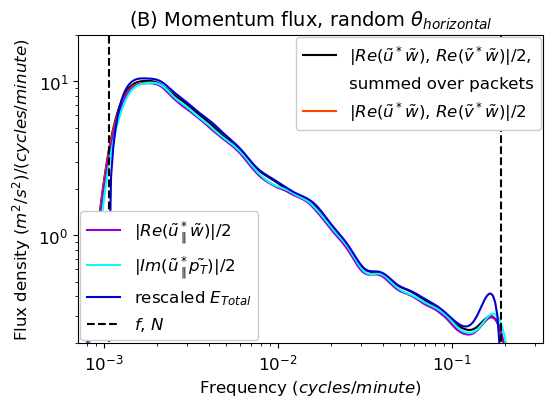

In [21]:
# Fig. 1(A, B), S5

fig, ax = plt.subplots(figsize=(6,4))
#ymin = 1E0
#ymax = 1E2
ymin = 2E-1
ymax = 2E1
line1, = ax.plot(frequency, temp_flux_eachpacket, 'k',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2,')
line2, = ax.plot(frequency, temp_flux_eachpacket, 'w', alpha=0,
                 label = 'summed over packets')
line3, = ax.plot(frequency, temp_flux, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line4, = ax.plot(frequency, temp_flux_upw, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line5, = ax.plot(frequency, temp_flux_uppt, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'|$Im(\tilde{u}_\parallel^*\tilde{p_T})$|/2')
line6, = ax.plot(frequency, temp_scaled_energy, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_title(r'(A) Momentum flux, constant ${\theta}_{horizontal}$', fontsize=14)
#ax.set_title(r'(B) Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_title(r'Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2, line3], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line4, line5, line6, line7],
          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1b2.pdf', format='pdf', bbox_inches='tight');

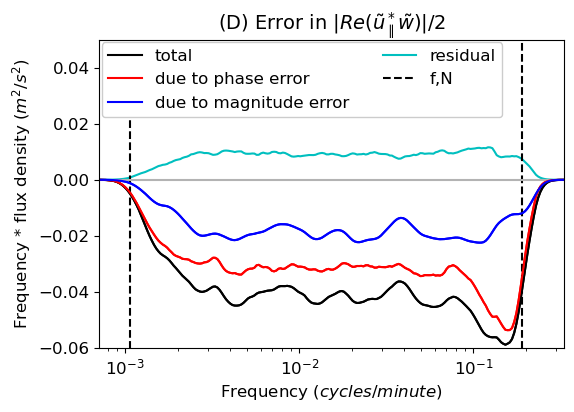

In [12]:
# Fig. 1D

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
plt.plot(frequency, frequency*(temp_flux_upw - temp_flux_upw_eachpacket), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket), 'b')
temp = temp_flux_upw - temp_flux_upw_eachpacket
temp = temp - (temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket)
temp = temp - (temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket)
plt.plot(frequency, frequency*temp, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [-ymax, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [-ymax, ymax],'--k')
plt.plot([np.abs(60*f/(2*np.pi))/1.5,1/3],[0, 0], color = [0.7,0.7,0.7])
plt.plot(frequency, frequency*(temp_flux_upw - temp_flux_upw_eachpacket), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket), 'b')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(-0.06, 0.05)
plt.xscale('log')
plt.title(r'(D) Error in |$Re(\tilde{u}_\parallel^*\tilde{w})$|/2', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            ncol=2, loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp3b2.pdf', format='pdf', bbox_inches='tight');

### Probability distributions of the ratio of output to input energy, momentum flux

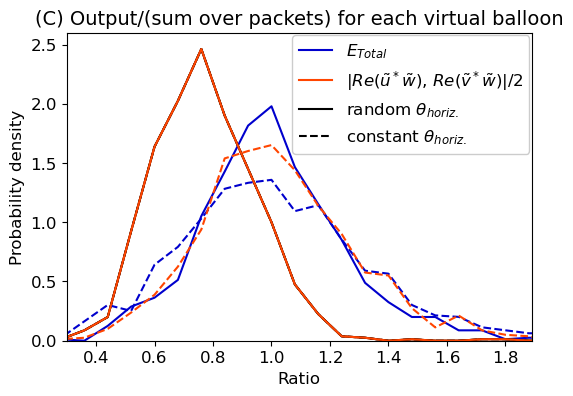

In [16]:
# Fig. 1C

container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq.npz')
#container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq_randomUpDown.npz')
data = [container[key] for key in container]
Etotal_total1                   = data[23]  # (n_balloons)
flux_total_eachpacket1          = data[10] # (n_balloons, n_packet_frequencies+1)

container = np.load('GaussEnv_ThHpiover6_1000B_20P_8omega0_Boussinesq.npz')
data = [container[key] for key in container]
Etotal_total2                   = data[23]  # (n_balloons)
flux_total_eachpacket2          = data[10] # (n_balloons, n_packet_frequencies+1)

flux_total_ratio1 = flux_total_eachpacket1[:,-1]/np.sum(flux_total_eachpacket1[:,:-1],axis=1)
Etotal_ratio1 = Etotal_total1[:,-1]/np.sum(Etotal_total1[:,:-1],axis=1)
flux_total_ratio2 = flux_total_eachpacket2[:,-1]/np.sum(flux_total_eachpacket2[:,:-1],axis=1)
Etotal_ratio2 = Etotal_total2[:,-1]/np.sum(Etotal_total2[:,:-1],axis=1)

n_bins = 25
bin_min = 0
bin_max = 2
bin_res = (bin_max - bin_min)/n_bins
bins = bin_min + bin_res*np.arange(1 + n_bins)
bin_centers = 0.5*(bins[:-1] + bins[1:])

hist, _ = np.histogram(flux_total_ratio1, bins = bins)
pdf_flux_total_ratio1 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(Etotal_ratio1, bins = bins)
pdf_Etotal_ratio1 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(flux_total_ratio2, bins = bins)
pdf_flux_total_ratio2 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(Etotal_ratio2, bins = bins)
pdf_Etotal_ratio2 = hist/(bin_res*np.sum(hist))



plt.figure(figsize=(6,4))
plt.plot(bin_centers, pdf_Etotal_ratio1, c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.plot(bin_centers, pdf_flux_total_ratio1, c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(bin_centers, pdf_flux_total_ratio1, 'k')
plt.plot(bin_centers, pdf_flux_total_ratio1, '--k')
plt.plot(bin_centers, pdf_Etotal_ratio2, c=matplotlib.colors.CSS4_COLORS['mediumblue'], linestyle='--')
plt.plot(bin_centers, pdf_flux_total_ratio2, c=matplotlib.colors.CSS4_COLORS['orangered'], linestyle='--')
plt.plot(bin_centers, pdf_flux_total_ratio1, c=matplotlib.colors.CSS4_COLORS['orangered'])
#plt.grid()
plt.xlim(bin_min, bin_max)
plt.xlim(0.3, 1.89)
plt.ylim(0,2.6)
plt.title('(C) Output/(sum over packets) for each virtual balloon', fontsize=14)
plt.xlabel('Ratio', fontsize=12)
plt.ylabel('Probability density', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2',
            r'random ${\theta}_{horiz.}$',
            r'constant ${\theta}_{horiz.}$'],
           loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp2b2.pdf', format='pdf', bbox_inches='tight');

### Plot of the ratio of Ep to Etotal

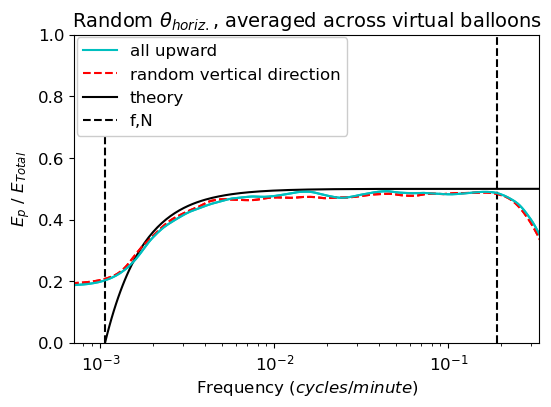

In [22]:
# Fig. S4

container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq.npz')
data = [container[key] for key in container]  
# Outputs: analyzed spectra
Ekh_spectrum1                      = data[42] # (nscales, n_balloons, n_packet_frequencies+1)
Ekv_spectrum1                      = data[43] # (nscales, n_balloons, n_packet_frequencies+1)
Ep_spectrum1                       = data[44] # (nscales, n_balloons, n_packet_frequencies+1)

container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq_randomUpDown.npz')
data = [container[key] for key in container]  
# Outputs: analyzed spectra
Ekh_spectrum2                      = data[42] # (nscales, n_balloons, n_packet_frequencies+1)
Ekv_spectrum2                      = data[43] # (nscales, n_balloons, n_packet_frequencies+1)
Ep_spectrum2                       = data[44] # (nscales, n_balloons, n_packet_frequencies+1)

# Constants, axes
rho_bar   = data[0]
Nref      = data[1]
f         = data[2]
frequency = data[3]
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

nscales = Ep_spectrum.shape[0]
n_balloons = Ep_spectrum.shape[1]
n_packet_frequencies = Ep_spectrum.shape[2] - 1

# Calculate the ratio of Ep to Etotal for each virtual balloon, and calculate quantiles
Etotal_spectrum_vb1 = Ep_spectrum1[:,:,-1] + Ekh_spectrum1[:,:,-1] + Ekv_spectrum1[:,:,-1]
Etotal_spectrum_vb2 = Ep_spectrum2[:,:,-1] + Ekh_spectrum2[:,:,-1] + Ekv_spectrum2[:,:,-1]
Ep_spectrum_vb1 = Ep_spectrum1[:,:,-1]
Ep_spectrum_vb2 = Ep_spectrum2[:,:,-1]
EpEtotalRatio1 = Ep_spectrum_vb1/Etotal_spectrum_vb1
EpEtotalRatio2 = Ep_spectrum_vb2/Etotal_spectrum_vb2
EpEtotalRatio_mean1 = np.nanmean(EpEtotalRatio1, axis=1)
EpEtotalRatio_mean2 = np.nanmean(EpEtotalRatio2, axis=1)

# The theoretical ratio of Ep to Etotal
freq_rad = 2*np.pi*frequency/60 # (rad/sec)
EpEtotalRatio_theory = 0.5*(Nref**2/freq_rad**2)*((freq_rad**2 - f**2)/(Nref**2 - f**2))

# Plot
plt.figure(figsize=(6,4))
ymin = 0
ymax = 1.0
plt.plot(frequency, EpEtotalRatio_mean1, 'c')
plt.plot(frequency, EpEtotalRatio_mean2, '--r')
plt.plot(frequency, EpEtotalRatio_theory, 'k')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [ymin, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [ymin, ymax],'--k')
plt.plot(frequency, EpEtotalRatio_mean2, '--r')
plt.plot(frequency, EpEtotalRatio_mean1, 'c')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin, ymax)
plt.xscale('log')
plt.title(r'Random ${\theta}_{horiz.}$, averaged across virtual balloons', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('$E_{p}$ / $E_{Total}$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(['all upward','random vertical direction','theory','f,N'],
            loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp102.pdf', format='pdf', bbox_inches='tight');